# Brazilian E-Commerce (Olist) — Raw EDA

Mục tiêu: đánh giá độ phù hợp cho propensity modeling. Đơn vị entity là
`customer_unique_id`; một record trong bảng sự kiện tương ứng một order.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import polars as pl

project_root = Path.cwd().resolve()
while project_root.parent != project_root and not (project_root / "src").exists():
    project_root = project_root.parent
if not (project_root / "src").exists():
    raise RuntimeError("Không tìm thấy project root chứa thư mục src")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.eda.config import DatasetSpec
from src.eda.descriptive import (
    describe_dataset,
    describe_entities,
    describe_quality,
    describe_temporal,
)
from src.eda.visualization import (
    plot_active_periods_per_entity,
    plot_entity_time_matrix,
    plot_missing_values,
    plot_records_over_time,
    plot_records_per_entity,
)

data_dir = project_root / "data" / "raw" / "brazilian"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)

def scalar_metrics(report):
    return {key: value for key, value in report.items() if not isinstance(value, pl.DataFrame)}

## 1. Load và chuẩn hóa bảng sự kiện

In [3]:
orders = pl.scan_csv(data_dir / "olist_orders_dataset.csv", try_parse_dates=True)
customers = pl.scan_csv(data_dir / "olist_customers_dataset.csv")
order_events = orders.join(
    customers.select("customer_id", "customer_unique_id"),
    on="customer_id",
    how="left",
)
spec = DatasetSpec(
    name="olist_orders",
    entity_col="customer_unique_id",
    time_col="order_purchase_timestamp",
    categorical_cols=("order_status",),
    id_cols=("order_id", "customer_id"),
)

## 2. Dataset overview

In [4]:
dataset_report = describe_dataset(order_events, spec)
print("Shape:", dataset_report["n_rows"], "rows x", dataset_report["n_cols"], "columns")
print("Dtype groups:", dataset_report["dtype_groups"])
display(dataset_report["overview"].sort("missing_frac", descending=True))
display(dataset_report["preview"])

Shape: 99441 rows x 9 columns
Dtype groups: {'numeric': [], 'string': ['order_id', 'customer_id', 'order_status', 'customer_unique_id'], 'categorical': [], 'temporal': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date'], 'boolean': [], 'other': []}


column,dtype,n_missing,missing_frac,n_unique_approx
str,str,i64,f64,i64
"""order_delivered_customer_date""","""Datetime(time_unit='us', time_…",2965,0.029817,97556
"""order_delivered_carrier_date""","""Datetime(time_unit='us', time_…",1783,0.01793,82009
"""order_approved_at""","""Datetime(time_unit='us', time_…",160,0.001609,89189
"""order_id""","""String""",0,0.0,97190
"""customer_id""","""String""",0,0.0,92419
"""order_status""","""String""",0,0.0,8
"""order_purchase_timestamp""","""Datetime(time_unit='us', time_…",0,0.0,90836
"""order_estimated_delivery_date""","""Datetime(time_unit='us', time_…",0,0.0,509
"""customer_unique_id""","""String""",0,0.0,94294


order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id
str,str,str,datetime[μs],datetime[μs],datetime[μs],datetime[μs],datetime[μs],str
"""47770eb9100c2d0c44946d9cf07ec6…","""41ce2a54c0b03bf3443c3d931a3670…","""delivered""",2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,"""3a653a41f6f9fc3d2a113cf8398680…"
"""e481f51cbdc54678b7cc49136f2d6a…","""9ef432eb6251297304e76186b10a92…","""delivered""",2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,"""7c396fd4830fd04220f754e42b4e5b…"
"""53cdb2fc8bc7dce0b6741e21502734…","""b0830fb4747a6c6d20dea0b8c802d7…","""delivered""",2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,"""af07308b275d755c9edb36a90c6182…"
"""ad21c59c0840e6cb83a9ceb5573f81…","""8ab97904e6daea8866dbdbc4fb7aad…","""delivered""",2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,"""72632f0f9dd73dfee390c9b22eb56d…"
"""949d5b44dbf5de918fe9c16f97b45f…","""f88197465ea7920adcdbec7375364d…","""delivered""",2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,"""7c142cf63193a1473d2e66489a9ae9…"


## 3. Data quality

In [5]:
quality_report = describe_quality(order_events, spec)
print(scalar_metrics(quality_report))
display(quality_report["column_quality"].sort("missing_pct", descending=True))

{'n_rows': 99441, 'n_cols': 9, 'n_duplicate_rows': 0, 'duplicate_row_pct': 0.0, 'n_missing_cells': 4908, 'missing_cell_pct': 0.5483988830898053, 'n_columns_with_missing': 3, 'constant_columns': [], 'all_missing_columns': []}


column,dtype,n_missing,missing_pct,n_unique_non_missing,is_constant,is_all_missing
str,str,i64,f64,i64,bool,bool
"""order_delivered_customer_date""","""Datetime(time_unit='us', time_…",2965,2.981668,95664,false,false
"""order_delivered_carrier_date""","""Datetime(time_unit='us', time_…",1783,1.793023,81018,false,false
"""order_approved_at""","""Datetime(time_unit='us', time_…",160,0.160899,90733,false,false
"""order_id""","""String""",0,0.0,99441,false,false
"""customer_id""","""String""",0,0.0,99441,false,false
"""order_status""","""String""",0,0.0,8,false,false
"""order_purchase_timestamp""","""Datetime(time_unit='us', time_…",0,0.0,98875,false,false
"""order_estimated_delivery_date""","""Datetime(time_unit='us', time_…",0,0.0,459,false,false
"""customer_unique_id""","""String""",0,0.0,96096,false,false


## 4. Temporal coverage

{'time_col': 'order_purchase_timestamp', 'n_records': 99441, 'n_valid_time': 99441, 'n_missing_or_invalid_time': 0, 'start_date': datetime.date(2016, 9, 4), 'end_date': datetime.date(2018, 10, 17), 'history_months': 26, 'observed_months': 25, 'missing_months': [datetime.date(2016, 11, 1)], 'mean_records_per_month': 3824.653846153846, 'std_records_per_month': 2704.448812637709, 'monthly_count_cv': 0.7071094330163659, 'min_records_per_month': 0, 'max_records_per_month': 7544}


month,n_records
date,u32
2016-09-01,4
2016-10-01,324
2016-11-01,0
2016-12-01,1
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700


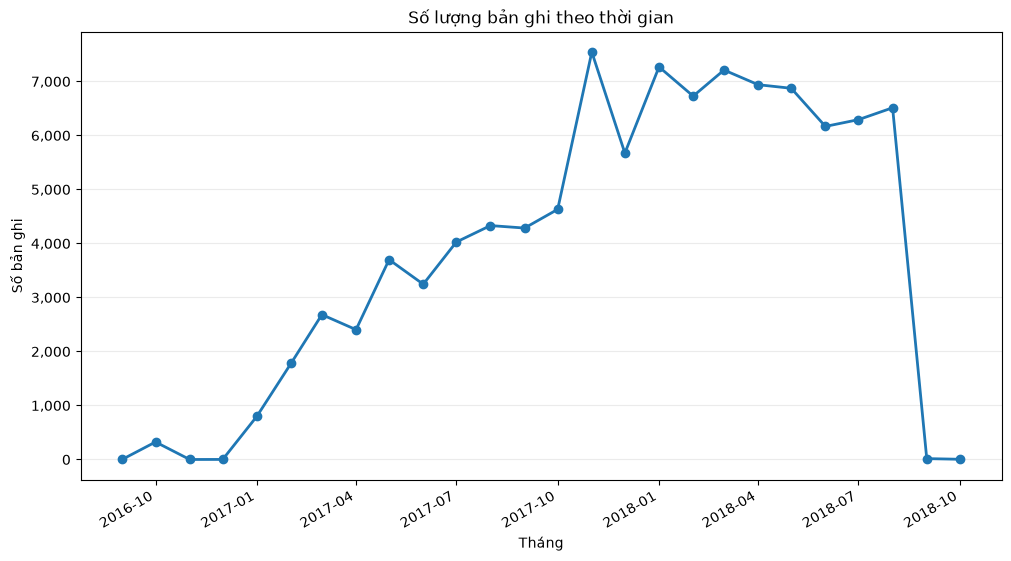

In [6]:
temporal_report = describe_temporal(order_events, spec)
print(scalar_metrics(temporal_report))
display(temporal_report["monthly_records"])

plot_records_over_time(temporal_report["monthly_records"])
plt.show()

## 5. Entity history

{'entity_col': 'customer_unique_id', 'n_unique_entities': 96096, 'n_records_missing_entity': 0, 'n_repeat_entities': 2997, 'repeat_entity_pct': 3.118756243756244, 'avg_records_per_entity': 1.0348089410589412, 'n_entities_active_2plus_months': 1797, 'active_2plus_months_pct': 1.870004995004995, 'min_history_days': 0, 'min_history_days_gt_0': 1, 'mean_history_days': 2.7229541292041293, 'median_history_days': 0.0, 'max_history_days': 633}


customer_unique_id,n_records,n_active_months,first_seen,last_seen,history_days
str,u32,u32,date,date,i64
"""0000366f3b9a7992bf8c76cfdf3221…",1,1,2018-05-10,2018-05-10,0
"""0000b849f77a49e4a4ce2b2a4ca5be…",1,1,2018-05-07,2018-05-07,0
"""0000f46a3911fa3c08054444833370…",1,1,2017-03-10,2017-03-10,0
"""0000f6ccb0745a6a4b88665a16c9f0…",1,1,2017-10-12,2017-10-12,0
"""0004aac84e0df4da2b147fca70cf82…",1,1,2017-11-14,2017-11-14,0
"""0004bd2a26a76fe21f786e4fbd8060…",1,1,2018-04-05,2018-04-05,0
"""00050ab1314c0e55a6ca13cf7181fe…",1,1,2018-04-20,2018-04-20,0
"""00053a61a98854899e70ed204dd4ba…",1,1,2018-02-28,2018-02-28,0
"""0005e1862207bf6ccc02e4228effd9…",1,1,2017-03-04,2017-03-04,0


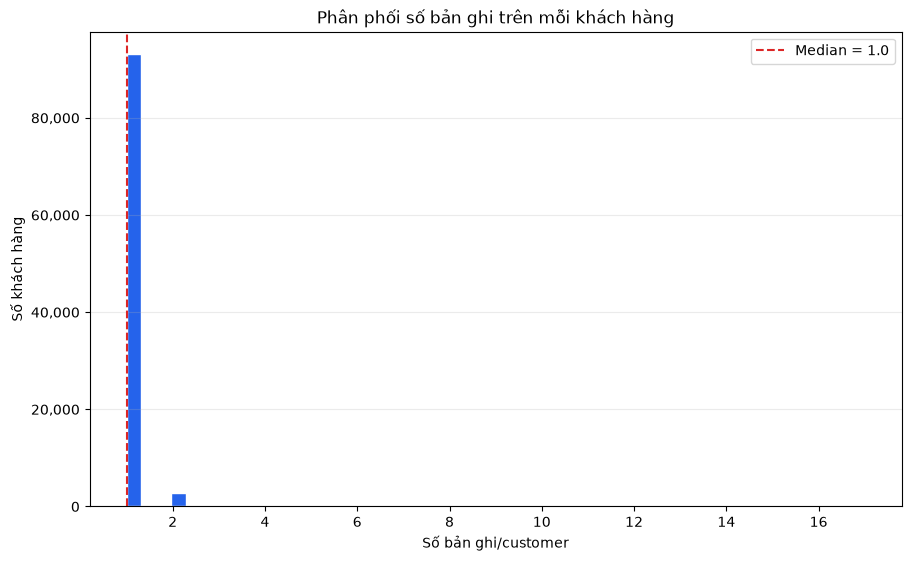

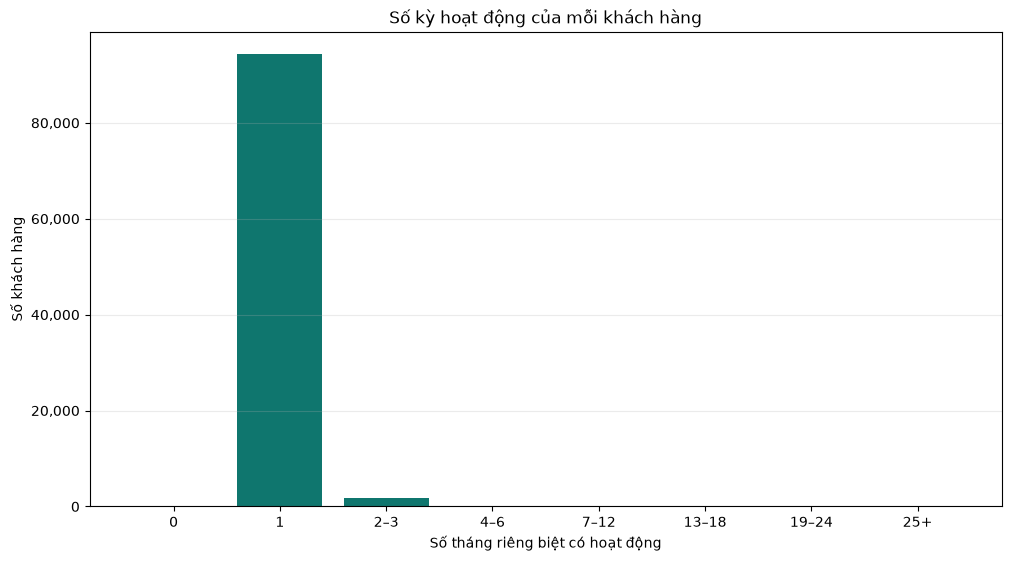

In [7]:
entity_report = describe_entities(order_events, spec)
print(scalar_metrics(entity_report))
display(entity_report["entity_history"].head(20))

plot_records_per_entity(entity_report["entity_history"])
plt.show()
plot_active_periods_per_entity(entity_report["entity_history"])
plt.show()

## 6. Missing values

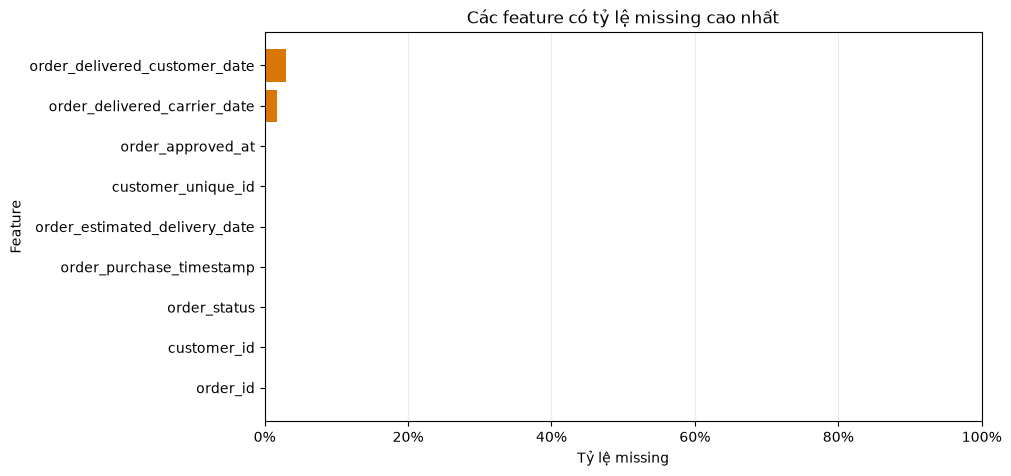

In [8]:
plot_missing_values(quality_report["column_quality"], top_n=20)
plt.show()

## 7. Customer activity matrix

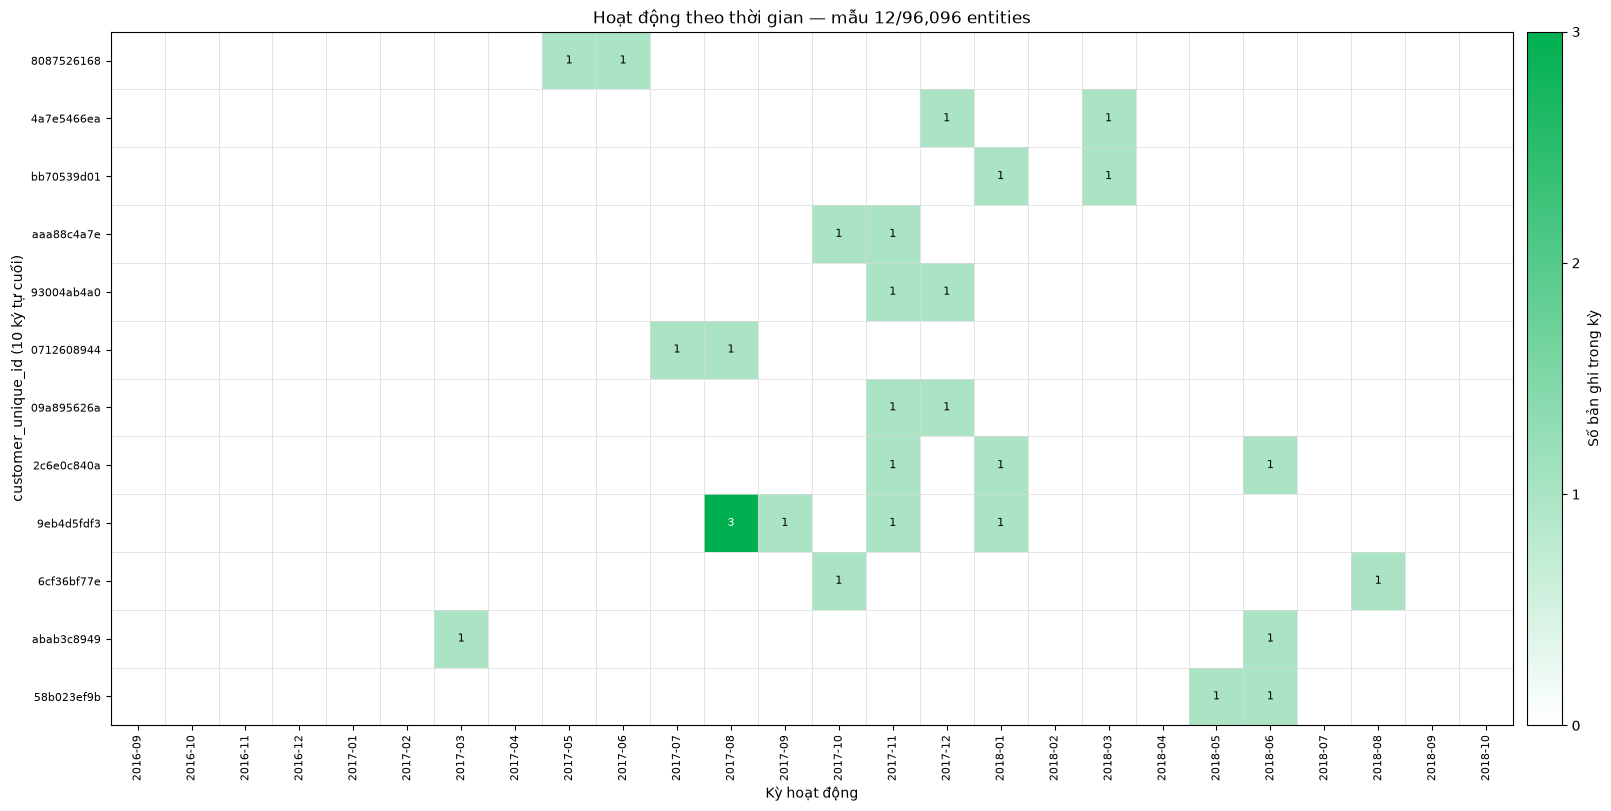

customer_unique_id,2016-09,2016-10,2016-11,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,…,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
str,i64,i64,i64,i64,i64,i64,i64,i64,i64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""bfc84496b1100cbbd83a6f80875261…",0,0,0,0,0,0,0,0,1,…,0,0,0,0,0,0,0,0,0,0
"""27d59fe7ff2ed894f826fd4a7e5466…",0,0,0,0,0,0,0,0,0,…,0,0,1,0,0,0,0,0,0,0
"""19cb65cc7310ae4eef4f15bb70539d…",0,0,0,0,0,0,0,0,0,…,1,0,1,0,0,0,0,0,0,0
"""cb5c545d96f39390b7f372aaa88c4a…",0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0
"""c4cf9b10d2668bfabb498d93004ab4…",0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0
"""f3d176999f9c1273045f7707126089…",0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0
"""d2ecc28fac1b377eefe7b209a89562…",0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0
"""8961b4ca2c5aceb7a78ea72c6e0c84…",0,0,0,0,0,0,0,0,0,…,1,0,0,0,0,1,0,0,0,0
"""47c1a3033b8b77b3ab6e109eb4d5fd…",0,0,0,0,0,0,0,0,0,…,1,0,0,0,0,0,0,0,0,0


customer_unique_id,active_periods,total_periods,coverage_pct,total_records
str,u32,i32,f64,u32
"""8961b4ca2c5aceb7a78ea72c6e0c84…",3,26,11.538462,3
"""130f4a32887cc549621b3c6cf36bf7…",2,26,7.692308,2
"""d2ecc28fac1b377eefe7b209a89562…",2,26,7.692308,2
"""47c1a3033b8b77b3ab6e109eb4d5fd…",4,26,15.384615,6
"""c4cf9b10d2668bfabb498d93004ab4…",2,26,7.692308,2
"""f3d176999f9c1273045f7707126089…",2,26,7.692308,2
"""6edeeed37ddd3dee7559f358b023ef…",2,26,7.692308,2
"""eeea20d93b0e221411defcabab3c89…",2,26,7.692308,2
"""cb5c545d96f39390b7f372aaa88c4a…",2,26,7.692308,2


Global coverage: ActivityCoverage(n_entities=96096, n_eligible_entities=1797, n_periods=26, n_active_entity_periods=98046, coverage_pct=3.9242007992007992, sample_size=12)


In [9]:
matrix_result = plot_entity_time_matrix(
    order_events,
    entity_col=spec.entity_col,
    timestamp_col=spec.time_col,
    sample_size=12,
    min_active_periods=2,
    seed=42,
    id_suffix=10,
    annotate=True,
    unique_col="order_id",
)
plt.show()
display(matrix_result.matrix)
display(matrix_result.entity_coverage)
print("Global coverage:", matrix_result.global_coverage)

## 8. Dataset-specific signals

In [10]:
order_status = (
    order_events.group_by("order_status")
    .agg(pl.len().alias("n_orders"))
    .sort("n_orders", descending=True)
    .collect()
)
display(order_status)

supporting_files = [
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
]
for filename in supporting_files:
    table = pl.scan_csv(data_dir / filename, try_parse_dates=True)
    print(filename, table.collect_schema())
    display(table.head(3).collect())

order_status,n_orders
str,u32
"""delivered""",96478
"""shipped""",1107
"""canceled""",625
"""unavailable""",609
"""invoiced""",314
"""processing""",301
"""created""",5
"""approved""",2


olist_order_items_dataset.csv Schema([('order_id', String), ('order_item_id', Int64), ('product_id', String), ('seller_id', String), ('shipping_limit_date', Datetime(time_unit='us', time_zone=None)), ('price', Float64), ('freight_value', Float64)])


order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
str,i64,str,str,datetime[μs],f64,f64
"""00010242fe8c5a6d1ba2dd792cb162…",1,"""4244733e06e7ecb4970a6e2683c13e…","""48436dade18ac8b2bce089ec2a0412…",2017-09-19 09:45:35,58.9,13.29
"""00018f77f2f0320c557190d7a144bd…",1,"""e5f2d52b802189ee658865ca93d83a…","""dd7ddc04e1b6c2c614352b383efe2d…",2017-05-03 11:05:13,239.9,19.93
"""000229ec398224ef6ca0657da4fc70…",1,"""c777355d18b72b67abbeef9df44fd0…","""5b51032eddd242adc84c38acab88f2…",2018-01-18 14:48:30,199.0,17.87


olist_order_payments_dataset.csv Schema([('order_id', String), ('payment_sequential', Int64), ('payment_type', String), ('payment_installments', Int64), ('payment_value', Float64)])


order_id,payment_sequential,payment_type,payment_installments,payment_value
str,i64,str,i64,f64
"""b81ef226f3fe1789b1e8b2acac839d…",1,"""credit_card""",8,99.33
"""a9810da82917af2d9aefd1278f1dcf…",1,"""credit_card""",1,24.39
"""25e8ea4e93396b6fa0d3dd708e76c1…",1,"""credit_card""",1,65.71


olist_order_reviews_dataset.csv Schema([('review_id', String), ('order_id', String), ('review_score', Int64), ('review_comment_title', String), ('review_comment_message', String), ('review_creation_date', Datetime(time_unit='us', time_zone=None)), ('review_answer_timestamp', Datetime(time_unit='us', time_zone=None))])


review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
str,str,i64,str,str,datetime[μs],datetime[μs]
"""7bc2406110b926393aa56f80a40eba…","""73fc7af87114b39712e6da79b0a377…",4,null,null,2018-01-18 00:00:00,2018-01-18 21:46:59
"""80e641a11e56f04c1ad469d5645fdf…","""a548910a1c6147796b98fdf73dbeba…",5,null,null,2018-03-10 00:00:00,2018-03-11 03:05:13
"""228ce5500dc1d8e020d8d1322874b6…","""f9e4b658b201a9f2ecdecbb34bed03…",5,null,null,2018-02-17 00:00:00,2018-02-18 14:36:24


olist_products_dataset.csv Schema([('product_id', String), ('product_category_name', String), ('product_name_lenght', Int64), ('product_description_lenght', Int64), ('product_photos_qty', Int64), ('product_weight_g', Int64), ('product_length_cm', Int64), ('product_height_cm', Int64), ('product_width_cm', Int64)])


product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
str,str,i64,i64,i64,i64,i64,i64,i64
"""1e9e8ef04dbcff4541ed26657ea517…","""perfumaria""",40,287,1,225,16,10,14
"""3aa071139cb16b67ca9e5dea641aaa…","""artes""",44,276,1,1000,30,18,20
"""96bd76ec8810374ed1b65e29197571…","""esporte_lazer""",46,250,1,154,18,9,15


olist_sellers_dataset.csv Schema([('seller_id', String), ('seller_zip_code_prefix', Int64), ('seller_city', String), ('seller_state', String)])


seller_id,seller_zip_code_prefix,seller_city,seller_state
str,i64,str,str
"""3442f8959a84dea7ee197c632cb2df…",13023,"""campinas""","""SP"""
"""d1b65fc7debc3361ea86b5f14c68d2…",13844,"""mogi guacu""","""SP"""
"""ce3ad9de960102d0677a81f5d0bb7b…",20031,"""rio de janeiro""","""RJ"""


## 9. Slide selection summary

Target chưa có sẵn. Có thể tạo propensity label như “có order tiếp theo trong
30/60/90 ngày”. Đây là dataset dễ hiểu nhưng repeat customer thường thấp.

In [11]:
slide_summary = pl.DataFrame(
    {
        "dataset": ["Brazilian Olist"],
        "n_rows": [dataset_report["n_rows"]],
        "n_columns": [dataset_report["n_cols"]],
        "n_entities": [entity_report["n_unique_entities"]],
        "history_months": [temporal_report["history_months"]],
        "missing_months": [len(temporal_report["missing_months"])],
        "repeat_entity_pct": [entity_report["repeat_entity_pct"]],
        "active_2plus_months_pct": [entity_report["active_2plus_months_pct"]],
        "missing_cell_pct": [quality_report["missing_cell_pct"]],
        "duplicate_row_pct": [quality_report["duplicate_row_pct"]],
        "target_status": ["Cần tạo future repeat-purchase label"],
    }
)
display(slide_summary)

dataset,n_rows,n_columns,n_entities,history_months,missing_months,repeat_entity_pct,active_2plus_months_pct,missing_cell_pct,duplicate_row_pct,target_status
str,i64,i64,i64,i64,i64,f64,f64,f64,f64,str
"""Brazilian Olist""",99441,9,96096,26,1,3.118756,1.870005,0.548399,0.0,"""Cần tạo future repeat-purchase…"
